#  Regresión Polinomial (Polynomial Regression) con Python y scikit-learn

**Técnica:** ajuste de curvas por mínimos cuadrados (*Least Squares Regression*) con un polinomio de grado **n = 4** (n > 3).

**Contenido**
1. Fundamentos teóricos del *Least Squares Regressor* para el ajuste de curvas
2. Modelo matemático y analítico
3. Pipeline de Machine Learning, etapa por etapa
   - 3.1 Recolección de datos
   - 3.2 Descripción y análisis del dataset
   - 3.3 Scatter plot
   - 3.4 Preparación de los datos (train / test)
   - 3.5 Selección del grado del polinomio
   - 3.6 Entrenamiento del modelo
   - 3.7 Verificación analítica (ecuación normal vs. scikit-learn)
   - 3.8 Evaluación (métricas y análisis de residuos)
   - 3.9 Visualización de la curva ajustada
   - 3.10 Predicción con datos nuevos




## 1. Fundamentos teóricos del Least Squares Regressor

### 1.1 ¿Qué problema resuelve?
La regresión estima la relación entre una variable de respuesta **Y** (dependiente) y una o más variables **X** (regresores, predictores o *features*). Los datos reales casi nunca caen exactamente sobre una curva, así que buscamos **la mejor curva posible**. La pregunta es qué significa "mejor".

### 1.2 Residuos
Para cada observación $i$, el **residuo** es la diferencia entre el valor observado y el valor que predice el modelo:

$$e_i = y_i - \hat{y}_i$$

### 1.3 El criterio de mínimos cuadrados
La mejor curva es la que **minimiza la suma de los residuos al cuadrado** (SSE o $SS_{error}$):

$$SSE = \sum_{i=1}^{m} (y_i - \hat{y}_i)^2$$

¿Por qué al cuadrado?
- Los errores positivos y negativos no se cancelan entre sí.
- Los errores grandes se penalizan más que los pequeños.
- La función resultante es diferenciable y tiene una solución única y directa.

### 1.4 Descomposición de la variación
Medimos la variación de Y respecto a su promedio $\bar{y}$:

$$SS_{total} = \sum (y_i - \bar{y})^2 \qquad SS_{regression} = \sum (\hat{y}_i - \bar{y})^2 \qquad SS_{error} = \sum (y_i - \hat{y}_i)^2$$

$$SS_{total} = SS_{regression} + SS_{error}$$

### 1.5 Coeficiente de determinación $R^2$
Es la proporción de la variación de Y que explica el modelo:

$$R^2 = \frac{SS_{regression}}{SS_{total}} = \frac{SS_{total}-SS_{error}}{SS_{total}} = 1 - \frac{SS_{error}}{SS_{total}}$$

**Advertencias importantes** (tomadas del material de referencia):
- Un $R^2$ alto no garantiza un buen modelo, y uno bajo no siempre implica un mal modelo.
- $R^2$ no detecta sesgo, por eso se **analizan los residuos** (deben ser aproximadamente normales y sin patrones).
- El modelo solo es válido dentro del **rango de datos** usado para ajustarlo (no extrapolar).

## 2. Modelo matemático y analítico

### 2.1 El modelo polinomial
Con una sola variable $x$ y un polinomio de grado $n$:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_n x^n$$

Aunque la curva no es una recta, el modelo es **lineal con respecto a los coeficientes** $\beta_j$. Por eso se resuelve con la misma regresión lineal por mínimos cuadrados: solo cambiamos las entradas. Tratamos $x, x^2, \dots, x^n$ como si fueran $n$ regresores distintos (una regresión lineal múltiple sobre variables derivadas de $x$).

### 2.2 Forma matricial
Con $m$ observaciones, construimos la **matriz de Vandermonde** $\mathbf{X}$ (tamaño $m \times (n+1)$):

$$
\mathbf{X}=\begin{bmatrix}
1 & x_1 & x_1^2 & \cdots & x_1^n\\
1 & x_2 & x_2^2 & \cdots & x_2^n\\
\vdots & \vdots & \vdots & & \vdots\\
1 & x_m & x_m^2 & \cdots & x_m^n
\end{bmatrix},\quad
\boldsymbol{\beta}=\begin{bmatrix}\beta_0\\ \beta_1\\ \vdots\\ \beta_n\end{bmatrix},\quad
\mathbf{y}=\begin{bmatrix}y_1\\ y_2\\ \vdots\\ y_m\end{bmatrix}
$$

El modelo es $\hat{\mathbf{y}} = \mathbf{X}\boldsymbol{\beta}$ y la función a minimizar es:

$$SSE(\boldsymbol{\beta}) = (\mathbf{y}-\mathbf{X}\boldsymbol{\beta})^{T}(\mathbf{y}-\mathbf{X}\boldsymbol{\beta})$$

### 2.3 Solución analítica (ecuación normal)
Derivamos respecto a $\boldsymbol{\beta}$ y la igualamos a cero:

$$\frac{\partial\, SSE}{\partial \boldsymbol{\beta}} = -2\,\mathbf{X}^{T}(\mathbf{y}-\mathbf{X}\boldsymbol{\beta}) = 0 \;\;\Rightarrow\;\; \mathbf{X}^{T}\mathbf{X}\,\boldsymbol{\beta}=\mathbf{X}^{T}\mathbf{y}$$

$$\boxed{\boldsymbol{\beta}=(\mathbf{X}^{T}\mathbf{X})^{-1}\mathbf{X}^{T}\mathbf{y}}$$

En la sección 3.7 calcularemos esta fórmula a mano con NumPy y la compararemos con scikit-learn. En la práctica, scikit-learn no invierte la matriz directamente: usa un método numéricamente más estable (mínimos cuadrados vía SVD), pero el resultado es el mismo.

### 2.4 Elección del grado $n$
- **Grado muy bajo** → *subajuste* (underfitting): la curva es demasiado simple y deja patrones en los residuos.
- **Grado muy alto** → *sobreajuste* (overfitting): la curva memoriza el ruido y falla con datos nuevos.
- En este tutorial usamos $n=4$ (cumple $n>3$) y lo justificamos comparando varios grados en la sección 3.5.

## 3. Pipeline de Machine Learning

### 3.0 Importación de librerías

In [ ]:
import numpy as np  # NumPy: arreglos numéricos y álgebra lineal
import pandas as pd  # Pandas: tablas (DataFrame) para organizar y describir los datos
import matplotlib.pyplot as plt  # Matplotlib: gráficas (scatter plot, curvas, histogramas)
from scipy import stats  # SciPy stats: pruebas de normalidad y gráfica Q-Q de los residuos
from sklearn.model_selection import train_test_split, cross_val_score  # Separar train/test y validación cruzada
from sklearn.preprocessing import PolynomialFeatures  # Genera las columnas x, x^2, ..., x^n
from sklearn.linear_model import LinearRegression  # Regresión lineal por mínimos cuadrados (OLS)
from sklearn.pipeline import make_pipeline  # Encadena transformación polinomial + regresión en un solo objeto
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # Métricas de evaluación

np.random.seed(42)  # Fija la semilla para que los resultados sean reproducibles
plt.rcParams["figure.figsize"] = (8, 5)  # Tamaño por defecto de todas las figuras
plt.rcParams["axes.grid"] = True  # Activa la cuadrícula en todas las gráficas

### 3.1 Etapa 1: Recolección de datos

En un proyecto real los datos vienen de un archivo, una base de datos o un sensor. Aquí **generamos un dataset sintético** a partir de un polinomio de grado 4 conocido, al que le sumamos ruido aleatorio. Así sabemos cuál es la "verdad" y podemos comprobar si el modelo la recupera.

Polinomio verdadero:

$$y = 5 + 2x - 3x^2 - x^3 + 0.5x^4 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\,2^2)$$

> Si quisieras usar datos propios, reemplaza esta celda por `datos = pd.read_csv("tu_archivo.csv")` y ajusta los nombres de columnas.

In [ ]:
m = 150  # Número de observaciones (filas) del dataset
x = np.random.uniform(-3, 3, m)  # Variable de entrada X: 150 valores aleatorios entre -3 y 3
coef_verdaderos = [5, 2, -3, -1, 0.5]  # Coeficientes reales [b0, b1, b2, b3, b4] del polinomio de grado 4
y_real = sum(c * x**k for k, c in enumerate(coef_verdaderos))  # Calcula b0 + b1*x + b2*x^2 + b3*x^3 + b4*x^4
ruido = np.random.normal(0, 2, m)  # Ruido aleatorio normal con media 0 y desviación estándar 2
y = y_real + ruido  # Variable de respuesta Y: curva verdadera más ruido (lo que "mediríamos")

datos = pd.DataFrame({"x": x, "y": y})  # Organiza X y Y en una tabla de Pandas
datos.head()  # Muestra las primeras 5 filas para confirmar que se cargó bien

,x,y
0,-0.752759,1.996912
1,2.704286,-3.963531
2,1.391964,1.081873
3,0.591951,2.649297
4,-2.063888,8.242617


### 3.2 Etapa 2: Descripción y análisis del dataset

Antes de modelar hay que conocer los datos: tamaño, tipos, valores faltantes, rangos y relación entre variables. Recuerda que la regresión requiere **datos continuos** (nivel de medición de intervalo o razón).

In [ ]:
print("Dimensiones (filas, columnas):", datos.shape)  # Cuántas observaciones y variables hay
print("\nTipos de datos y valores no nulos:")  # Título de la sección con salto de línea previo
datos.info()  # Muestra el tipo de cada columna (deben ser numéricas continuas) y los no nulos

Dimensiones (filas, columnas): (150, 2)

Tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       150 non-null    float64
 1   y       150 non-null    float64
dtypes: float64(2)
memory usage: 2.5 KB


In [ ]:
print("Valores faltantes por columna:")  # Título de la revisión de datos faltantes
print(datos.isnull().sum())  # Cuenta los valores nulos de cada columna (esperamos 0)
print("\nEstadísticos descriptivos:")  # Título de la tabla de estadísticos
datos.describe().round(3)  # Media, desviación, mínimo, cuartiles y máximo de x e y

Valores faltantes por columna:
x    0
y    0
dtype: int64

Estadísticos descriptivos:


,x,y
count,150.000,150.000
mean,-0.163,4.582
std,1.779,8.916
min,-2.967,-7.312
25%,-1.711,-0.907
50%,-0.311,2.210
75%,1.498,6.751
max,2.921,38.461


In [ ]:
r_pearson = datos["x"].corr(datos["y"])  # Coeficiente de correlación lineal de Pearson entre x e y
print(f"Correlación lineal de Pearson (x, y): {r_pearson:.4f}")  # Lo imprime con 4 decimales

Correlación lineal de Pearson (x, y): -0.6911


**Interpretación.** Obtenemos una correlación moderada (alrededor de -0.69). Pero la correlación de Pearson solo mide asociación **lineal**: no dice si una curva describiría mucho mejor los datos que una recta. Aunque r sea moderada, la relación puede ser claramente **curva**. El scatter plot de la siguiente etapa lo confirma visualmente.

### 3.3 Etapa 3: Scatter plot (diagrama de dispersión)

La gráfica de dispersión es la herramienta para decidir si conviene un modelo lineal o uno de mayor grado.

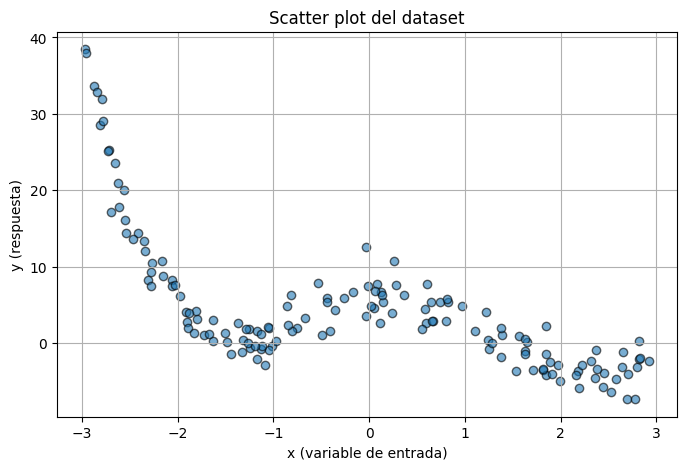

In [ ]:
fig, ax = plt.subplots()  # Crea la figura (fig) y el área de dibujo (ax)
ax.scatter(datos["x"], datos["y"], alpha=0.6, edgecolor="k")  # Dibuja cada observación como un punto
ax.set_xlabel("x (variable de entrada)")  # Etiqueta del eje horizontal
ax.set_ylabel("y (respuesta)")  # Etiqueta del eje vertical
ax.set_title("Scatter plot del dataset")  # Título de la gráfica
plt.show()  # Muestra la gráfica en el notebook

**Interpretación.** Los puntos siguen una curva con varios cambios de dirección, no una recta. Esto justifica probar un polinomio de grado alto.

### 3.4 Etapa 4: Preparación de los datos (train / test)

Separamos los datos en dos conjuntos:
- **Entrenamiento (80 %)**: el modelo aprende los coeficientes con ellos.
- **Prueba (20 %)**: se reservan para evaluar con datos que el modelo **nunca vio**.

scikit-learn exige que X sea una matriz 2D (filas × columnas), por eso usamos doble corchete.

In [ ]:
X = datos[["x"]].values  # Matriz X de forma (m, 1): doble corchete para que sea 2D; .values la vuelve arreglo NumPy
y_vec = datos["y"].values  # Vector y de forma (m,): la respuesta como arreglo NumPy

X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos al azar en entrenamiento y prueba
    X, y_vec,  # Variables de entrada y de respuesta que se van a dividir
    test_size=0.2,  # 20 % de las observaciones se reservan para prueba
    random_state=42  # Semilla para que la división sea siempre la misma
)  # Cierra la llamada a train_test_split

print("Observaciones de entrenamiento:", X_train.shape[0])  # Cuántas filas quedaron para entrenar
print("Observaciones de prueba:", X_test.shape[0])  # Cuántas filas quedaron para probar

Observaciones de entrenamiento: 120
Observaciones de prueba: 30


### 3.5 Etapa 5: Selección del grado del polinomio

Probamos grados del 1 al 9 y comparamos el error en **entrenamiento** contra el error en **prueba** y el $R^2$ de **validación cruzada** (5 pliegues sobre los datos de entrenamiento).

- Si el error de entrenamiento baja pero el de prueba sube, hay **sobreajuste**.
- Buscamos el grado donde el error de prueba deja de mejorar de forma importante.

In [ ]:
resultados = []  # Lista donde guardaremos las métricas de cada grado

for g in range(1, 10):  # Recorre los grados 1, 2, ..., 9
    modelo_g = make_pipeline(  # Crea un pipeline para el grado actual
        PolynomialFeatures(degree=g, include_bias=False),  # Genera x, x^2, ..., x^g (sin la columna de unos)
        LinearRegression()  # Ajusta los coeficientes por mínimos cuadrados (incluye el intercepto b0)
    )  # Cierra la creación del pipeline
    modelo_g.fit(X_train, y_train)  # Entrena el modelo con los datos de entrenamiento
    rmse_train = np.sqrt(mean_squared_error(y_train, modelo_g.predict(X_train)))  # Error RMSE sobre entrenamiento
    rmse_test = np.sqrt(mean_squared_error(y_test, modelo_g.predict(X_test)))  # Error RMSE sobre prueba
    r2_cv = cross_val_score(modelo_g, X_train, y_train, cv=5, scoring="r2").mean()  # R2 promedio en validación cruzada
    resultados.append({"grado": g, "RMSE_train": rmse_train, "RMSE_test": rmse_test, "R2_CV": r2_cv})  # Guarda la fila

tabla_grados = pd.DataFrame(resultados)  # Convierte la lista de resultados en una tabla
tabla_grados.round(3)  # Muestra la tabla redondeada a 3 decimales

,grado,RMSE_train,RMSE_test,R2_CV
0,1,6.123,7.528,0.365
1,2,5.645,6.420,0.400
2,3,4.014,3.801,0.673
3,4,2.137,1.322,0.893
4,5,2.137,1.328,0.892
5,6,2.103,1.474,0.896
6,7,2.099,1.455,0.895
7,8,2.041,1.460,0.901
8,9,2.035,1.478,0.897


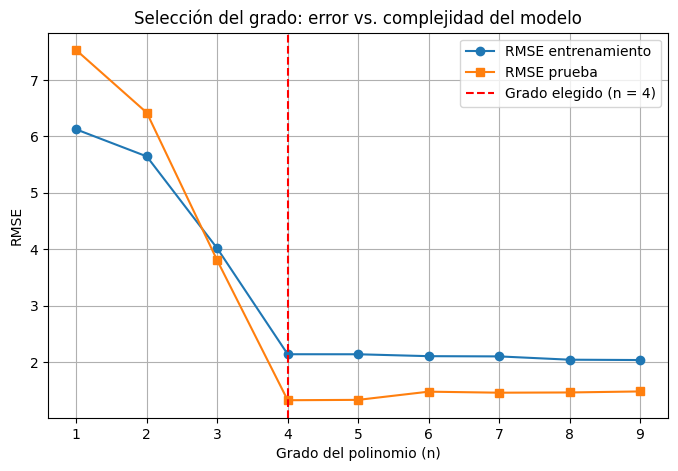

In [ ]:
fig, ax = plt.subplots()  # Crea la figura y el área de dibujo
ax.plot(tabla_grados["grado"], tabla_grados["RMSE_train"], "o-", label="RMSE entrenamiento")  # Curva de error de entrenamiento
ax.plot(tabla_grados["grado"], tabla_grados["RMSE_test"], "s-", label="RMSE prueba")  # Curva de error de prueba
ax.axvline(4, color="red", linestyle="--", label="Grado elegido (n = 4)")  # Línea vertical en el grado elegido
ax.set_xlabel("Grado del polinomio (n)")  # Etiqueta del eje horizontal
ax.set_ylabel("RMSE")  # Etiqueta del eje vertical
ax.set_title("Selección del grado: error vs. complejidad del modelo")  # Título de la gráfica
ax.legend()  # Muestra la leyenda
plt.show()  # Muestra la gráfica

**Interpretación.** Los grados 1 a 3 tienen un error alto (subajuste). A partir del grado 4 el error de prueba prácticamente deja de mejorar, y los grados mayores no aportan una mejora real a pesar de ser más complejos. Elegimos **n = 4**, que además cumple el requisito $n > 3$.

### 3.6 Etapa 6: Entrenamiento del modelo (grado 4)

Construimos el modelo final con un `Pipeline` de dos pasos:
1. `PolynomialFeatures(degree=4)`: transforma $x$ en $[x, x^2, x^3, x^4]$.
2. `LinearRegression()`: encuentra los $\beta_j$ que minimizan el SSE.

In [ ]:
GRADO = 4  # Grado del polinomio (n = 4, cumple la condición n > 3)

modelo = make_pipeline(  # Crea el pipeline del modelo final
    PolynomialFeatures(degree=GRADO, include_bias=False),  # Paso 1: expande x en x, x^2, x^3, x^4
    LinearRegression()  # Paso 2: regresión lineal por mínimos cuadrados sobre las columnas expandidas
)  # Cierra la creación del pipeline

modelo.fit(X_train, y_train)  # Entrena: calcula los coeficientes que minimizan el SSE en entrenamiento

reg = modelo.named_steps["linearregression"]  # Extrae el paso de regresión lineal ya entrenado
beta_sklearn = np.concatenate(([reg.intercept_], reg.coef_))  # Une el intercepto b0 con los coeficientes b1..b4

tabla_coef = pd.DataFrame({  # Tabla comparando los coeficientes verdaderos con los estimados
    "coeficiente": [f"b{j}" for j in range(GRADO + 1)],  # Nombres b0, b1, b2, b3, b4
    "verdadero": coef_verdaderos,  # Valores reales usados para generar los datos
    "estimado (sklearn)": beta_sklearn  # Valores que encontró el modelo
})  # Cierra la creación de la tabla
tabla_coef.round(4)  # Muestra la tabla con 4 decimales

,coeficiente,verdadero,estimado (sklearn)
0,b0,5.0,5.6558
1,b1,2.0,1.8343
2,b2,-3.0,-3.5802
3,b3,-1.0,-0.9510
4,b4,0.5,0.5805


**Interpretación.** Los coeficientes estimados quedan cerca de los verdaderos. No son idénticos porque los datos tienen ruido aleatorio, que es precisamente lo que ocurre en un caso real.

La ecuación ajustada es:

In [ ]:
terminos = [f"{beta_sklearn[j]:+.3f}·x^{j}" for j in range(GRADO + 1)]  # Cada término "coef·x^j" con su signo
print("ŷ = " + " ".join(terminos))  # Imprime la ecuación de regresión completa

ŷ = +5.656·x^0 +1.834·x^1 -3.580·x^2 -0.951·x^3 +0.581·x^4


### 3.7 Etapa 7: Verificación analítica (ecuación normal vs. scikit-learn)

Aplicamos a mano la fórmula de la sección 2.3, $\boldsymbol{\beta}=(\mathbf{X}^{T}\mathbf{X})^{-1}\mathbf{X}^{T}\mathbf{y}$, y la comparamos con el resultado de scikit-learn.

In [ ]:
X_vander = np.vander(X_train.ravel(), N=GRADO + 1, increasing=True)  # Matriz de Vandermonde: columnas 1, x, x^2, x^3, x^4
XtX = X_vander.T @ X_vander  # Calcula X^T X (matriz cuadrada de tamaño 5 x 5)
Xty = X_vander.T @ y_train  # Calcula X^T y (vector de tamaño 5)
beta_normal = np.linalg.solve(XtX, Xty)  # Resuelve XtX · beta = Xty (equivale a invertir, pero más estable)

comparacion = pd.DataFrame({  # Tabla para comparar ambos métodos
    "coeficiente": [f"b{j}" for j in range(GRADO + 1)],  # Nombres b0 a b4
    "ecuación normal (NumPy)": beta_normal,  # Resultado de la fórmula analítica
    "scikit-learn": beta_sklearn  # Resultado de LinearRegression
})  # Cierra la creación de la tabla
display(comparacion.round(6))  # Muestra la tabla con 6 decimales

print("¿Coinciden ambos métodos?", np.allclose(beta_normal, beta_sklearn))  # True si las diferencias son numéricamente nulas

,coeficiente,ecuación normal (NumPy),scikit-learn
0,b0,5.655762,5.655762
1,b1,1.834341,1.834341
2,b2,-3.580222,-3.580222
3,b3,-0.951040,-0.951040
4,b4,0.580523,0.580523


¿Coinciden ambos métodos? True


**Interpretación.** Ambos métodos dan los mismos coeficientes: scikit-learn es una implementación eficiente y estable de la misma solución analítica de mínimos cuadrados.

### 3.8 Etapa 8: Evaluación del modelo (métricas)

Evaluamos con las métricas más usadas para regresión:

| Métrica | Fórmula | Qué indica |
|---|---|---|
| MSE | $\frac{1}{m}\sum(y_i-\hat{y}_i)^2$ | Error cuadrático medio |
| RMSE | $\sqrt{MSE}$ | Error típico, en las unidades de Y |
| MAE | $\frac{1}{m}\sum\lvert y_i-\hat{y}_i\rvert$ | Error absoluto promedio |
| $R^2$ | $1 - SS_{error}/SS_{total}$ | Proporción de variación de Y explicada |
| $R^2$ ajustado | $1-(1-R^2)\frac{m-1}{m-n-1}$ | $R^2$ penalizado por el número de términos |

#### 3.8.1 Métricas en entrenamiento y en prueba

In [ ]:
y_pred_train = modelo.predict(X_train)  # Predicciones del modelo sobre los datos de entrenamiento
y_pred_test = modelo.predict(X_test)  # Predicciones del modelo sobre los datos de prueba (nunca vistos)

def calcular_metricas(y_obs, y_est, n_grado):  # Función que devuelve todas las métricas de un conjunto de datos
    n_obs = len(y_obs)  # Número de observaciones del conjunto
    mse = mean_squared_error(y_obs, y_est)  # Error cuadrático medio
    rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
    mae = mean_absolute_error(y_obs, y_est)  # Error absoluto medio
    r2 = r2_score(y_obs, y_est)  # Coeficiente de determinación R2
    r2_aj = 1 - (1 - r2) * (n_obs - 1) / (n_obs - n_grado - 1)  # R2 ajustado por el número de términos del polinomio
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2, "R2 ajustado": r2_aj}  # Devuelve las métricas en un diccionario

metricas = pd.DataFrame({  # Tabla comparando entrenamiento y prueba
    "Entrenamiento": calcular_metricas(y_train, y_pred_train, GRADO),  # Métricas con los datos de entrenamiento
    "Prueba": calcular_metricas(y_test, y_pred_test, GRADO)  # Métricas con los datos de prueba
})  # Cierra la creación de la tabla
metricas.round(4)  # Muestra la tabla con 4 decimales

,Entrenamiento,Prueba
MSE,4.5683,1.7475
RMSE,2.1374,1.3219
MAE,1.7104,1.0574
R2,0.9368,0.9835
R2 ajustado,0.9346,0.9808


**Interpretación.** El modelo **generaliza bien**: en prueba el error no es mayor que en entrenamiento (si fuera mucho mayor, sería señal de sobreajuste). El RMSE de entrenamiento queda cerca de 2, que es la desviación estándar del ruido que agregamos: no se puede predecir mejor que ese ruido irreducible. El RMSE de prueba salió algo menor porque el conjunto de prueba es pequeño (30 puntos) y por azar contiene ruido más suave; con otra semilla puede variar.

#### 3.8.2 Descomposición de sumas de cuadrados
Verificamos con números la identidad $SS_{total}=SS_{regression}+SS_{error}$ y las tres fórmulas equivalentes de $R^2$ (sobre los datos de entrenamiento).

In [ ]:
y_media = np.mean(y_train)  # Promedio de Y en entrenamiento (y barra)
ss_total = np.sum((y_train - y_media) ** 2)  # SS total: variación de Y respecto a su promedio
ss_reg = np.sum((y_pred_train - y_media) ** 2)  # SS regresión: variación explicada por el modelo
ss_error = np.sum((y_train - y_pred_train) ** 2)  # SS error: variación NO explicada (el SSE que se minimizó)

print(f"SS_total              = {ss_total:.4f}")  # Imprime la variación total
print(f"SS_regresión          = {ss_reg:.4f}")  # Imprime la variación explicada
print(f"SS_error              = {ss_error:.4f}")  # Imprime la variación no explicada
print(f"SS_regresión + SS_error = {ss_reg + ss_error:.4f}  (debe igualar a SS_total)")  # Comprueba la identidad
print()  # Línea en blanco para separar bloques
print(f"R2 (A) SS_reg / SS_total          = {ss_reg / ss_total:.6f}")  # Fórmula A del material de referencia
print(f"R2 (B) (SS_total - SS_error)/SS_total = {(ss_total - ss_error) / ss_total:.6f}")  # Fórmula B
print(f"R2 (C) 1 - SS_error / SS_total    = {1 - ss_error / ss_total:.6f}")  # Fórmula C

SS_total              = 8668.0091
SS_regresión          = 8119.8168
SS_error              = 548.1924
SS_regresión + SS_error = 8668.0091  (debe igualar a SS_total)

R2 (A) SS_reg / SS_total          = 0.936757
R2 (B) (SS_total - SS_error)/SS_total = 0.936757
R2 (C) 1 - SS_error / SS_total    = 0.936757


**Interpretación.** Las tres fórmulas dan exactamente el mismo $R^2$ y la suma $SS_{regression}+SS_{error}$ coincide con $SS_{total}$, tal como establece la teoría.

#### 3.8.3 Análisis de residuos
El $R^2$ no detecta sesgo, así que revisamos los residuos. Un buen modelo tiene residuos:
- aproximadamente **normales**,
- **sin patrón** al graficarlos contra el valor predicho,
- con **varianza constante** (homocedasticidad).

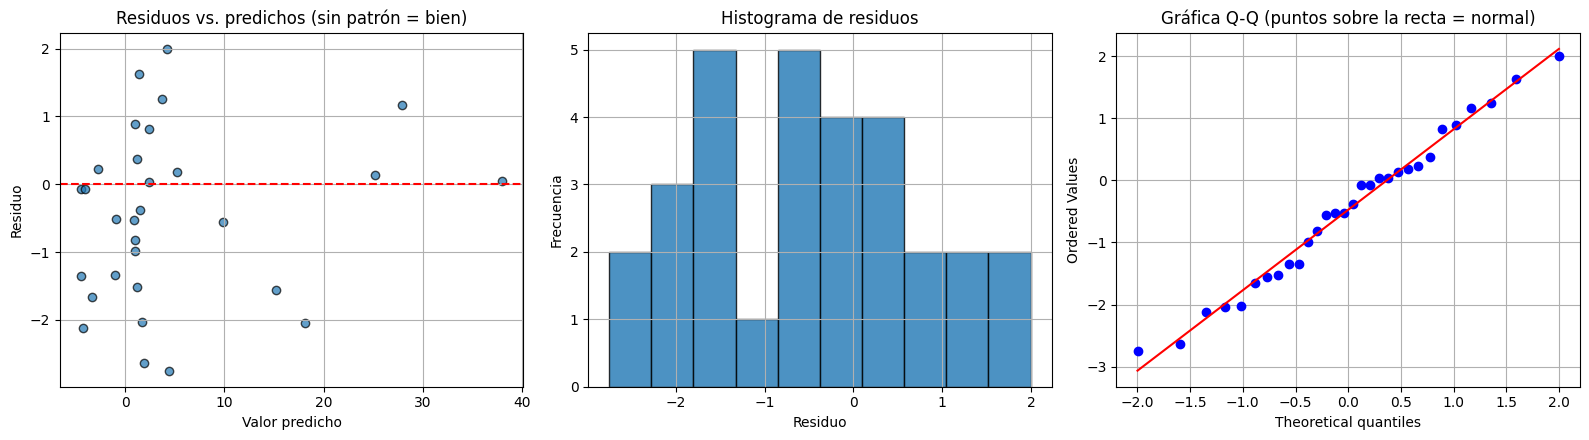

In [ ]:
residuos = y_test - y_pred_test  # Residuos en prueba: observado menos predicho

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))  # Crea una figura con 3 gráficas en una fila

ejes[0].scatter(y_pred_test, residuos, alpha=0.7, edgecolor="k")  # Residuos contra valores predichos
ejes[0].axhline(0, color="red", linestyle="--")  # Línea de referencia en cero
ejes[0].set_xlabel("Valor predicho")  # Etiqueta del eje horizontal
ejes[0].set_ylabel("Residuo")  # Etiqueta del eje vertical
ejes[0].set_title("Residuos vs. predichos (sin patrón = bien)")  # Título de la primera gráfica

ejes[1].hist(residuos, bins=10, edgecolor="k", alpha=0.8)  # Histograma de los residuos
ejes[1].set_xlabel("Residuo")  # Etiqueta del eje horizontal
ejes[1].set_ylabel("Frecuencia")  # Etiqueta del eje vertical
ejes[1].set_title("Histograma de residuos")  # Título de la segunda gráfica

stats.probplot(residuos, dist="norm", plot=ejes[2])  # Gráfica Q-Q: compara los residuos con una normal teórica
ejes[2].set_title("Gráfica Q-Q (puntos sobre la recta = normal)")  # Título de la tercera gráfica

plt.tight_layout()  # Acomoda las tres gráficas sin que se encimen
plt.show()  # Muestra la figura

In [ ]:
estadistico, p_valor = stats.shapiro(residuos)  # Prueba de Shapiro-Wilk: H0 = los residuos son normales
print(f"Shapiro-Wilk: estadístico = {estadistico:.4f}, p-value = {p_valor:.4f}")  # Imprime el resultado de la prueba
if p_valor > 0.05:  # Si p > 0.05 no se rechaza la hipótesis de normalidad
    print("Conclusión: no hay evidencia contra la normalidad de los residuos (el modelo es aplicable).")  # Caso favorable
else:  # Si p <= 0.05 se rechaza la normalidad
    print("Conclusión: los residuos NO parecen normales; conviene revisar el modelo.")  # Caso desfavorable

Shapiro-Wilk: estadístico = 0.9792, p-value = 0.8052
Conclusión: no hay evidencia contra la normalidad de los residuos (el modelo es aplicable).


### 3.9 Etapa 9: Visualización de la curva ajustada

Dibujamos la curva del modelo sobre los datos, junto con la curva verdadera (que en un caso real no conoceríamos).

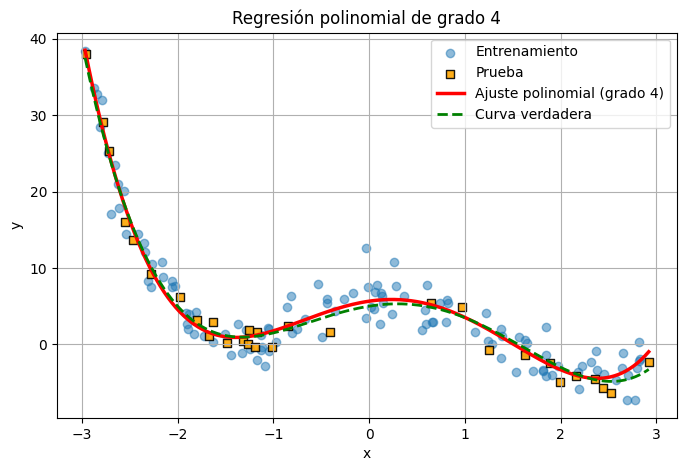

In [ ]:
x_curva = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)  # 300 puntos equiespaciados dentro del rango de datos (en 2D)
y_curva = modelo.predict(x_curva)  # Predicción del modelo en cada punto de la malla
y_curva_real = sum(c * x_curva.ravel() ** k for k, c in enumerate(coef_verdaderos))  # Polinomio verdadero en la misma malla

fig, ax = plt.subplots()  # Crea la figura y el área de dibujo
ax.scatter(X_train, y_train, alpha=0.5, label="Entrenamiento")  # Puntos de entrenamiento
ax.scatter(X_test, y_test, alpha=0.9, marker="s", color="orange", edgecolor="k", label="Prueba")  # Puntos de prueba
ax.plot(x_curva, y_curva, color="red", linewidth=2.5, label=f"Ajuste polinomial (grado {GRADO})")  # Curva del modelo
ax.plot(x_curva, y_curva_real, color="green", linestyle="--", linewidth=2, label="Curva verdadera")  # Curva real
ax.set_xlabel("x")  # Etiqueta del eje horizontal
ax.set_ylabel("y")  # Etiqueta del eje vertical
ax.set_title("Regresión polinomial de grado 4")  # Título de la gráfica
ax.legend()  # Muestra la leyenda
plt.show()  # Muestra la gráfica

**Interpretación.** La curva roja (modelo) casi se superpone a la verde (verdad). Recuerda que el modelo solo es confiable **dentro del rango de x usado para entrenar**: fuera de él, un polinomio de grado alto puede dispararse.

### 3.10 Etapa 10: Predicción con datos nuevos

Usamos el modelo entrenado para estimar Y en valores de X que no estaban en el dataset (siempre dentro del rango, entre -3 y 3).

In [ ]:
x_nuevos = np.array([[-2.5], [0.0], [1.5], [2.8]])  # Cuatro valores nuevos de X, en forma 2D (filas x 1 columna)
y_nuevos = modelo.predict(x_nuevos)  # El modelo estima la respuesta para cada valor nuevo

predicciones = pd.DataFrame({"x nuevo": x_nuevos.ravel(), "y predicho": y_nuevos})  # Tabla con entradas y predicciones
predicciones.round(3)  # Muestra la tabla con 3 decimales

,x nuevo,y predicho
0,-2.5,16.230
1,0.0,5.656
2,1.5,0.081
3,2.8,-2.472


## 4. Conclusiones

1. La **regresión polinomial** es una regresión lineal por mínimos cuadrados aplicada a las columnas $x, x^2, \dots, x^n$. Es lineal en los coeficientes, aunque la curva no sea una recta.
2. Los coeficientes se obtienen minimizando el SSE; la solución analítica es $\boldsymbol{\beta}=(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$, y scikit-learn la reproduce exactamente.
3. El **grado** es el hiperparámetro clave: poco grado causa subajuste y demasiado grado causa sobreajuste. Se elige comparando el error en datos de prueba o con validación cruzada.
4. El $R^2$ por sí solo no basta: hay que revisar las **métricas de error (RMSE, MAE)** y el **análisis de residuos** (normalidad y ausencia de patrones).
5. El modelo solo es válido **dentro del rango de datos** con el que se entrenó. No se debe extrapolar.
